# Objectifs d'apprentissage – Semaine 8

À l'issue de cette semaine, l'étudiant sera capable de :

- **Définir** la Transformée de Fourier Discrète (DFT) et la Transformée de Fourier Rapide (FFT).
- **Comprendre** la relation entre la DTFT, la DFT et la FFT.
- **Appliquer** la FFT pour analyser le contenu fréquentiel de signaux numériques.
- **Expliquer** le phénomène de fuite spectrale (spectral leakage) et son origine.
- **Utiliser** des fenêtres (Hamming, Hanning, Blackman) pour réduire les fuites spectrales.
- **Choisir** une fenêtre adaptée en fonction du compromis résolution/dynamique.
- **Interpréter** les spectres d'amplitude et de phase obtenus par FFT.
- **Mettre en œuvre** des analyses spectrales avancées (zero-padding, chevauchement).

# 1. Rappels théoriques

## 1.1 Transformée de Fourier Discrète (DFT)

Pour une séquence de longueur $N$, $x[0], x[1], \ldots, x[N-1]$, la DFT est définie par :

$$ X[k] = \sum_{n=0}^{N-1} x[n] \, e^{-j 2\pi k n / N}, \quad k = 0, 1, \ldots, N-1 $$

La DFT échantillonne la DTFT $X(e^{j\omega})$ aux fréquences $\omega_k = 2\pi k / N$.

Transformée inverse :

$$ x[n] = \frac{1}{N} \sum_{k=0}^{N-1} X[k] \, e^{j 2\pi k n / N} $$

## 1.2 FFT (Fast Fourier Transform)

La FFT est un algorithme efficace pour calculer la DFT en $O(N \log N)$ opérations au lieu de $O(N^2)$ pour la DFT directe.

En Python, `numpy.fft` et `scipy.fft` fournissent des implémentations optimisées.

## 1.3 Fuite spectrale (Spectral Leakage)

Lorsqu'on applique la DFT à un signal de durée finie, on tronque le signal (multiplication par une fenêtre rectangulaire). Cette troncature provoque des lobes secondaires dans le spectre : c'est la fuite spectrale.

## 1.4 Fenêtrage

Pour réduire la fuite spectrale, on multiplie le signal par une fenêtre qui s'atténue vers les bords (Hamming, Hanning, Blackman, etc.).

**Compromis** :
- Fenêtre rectangulaire : meilleure résolution, mais forte fuite spectrale.
- Fenêtres de Hamming/Hanning : réduction de la fuite, mais élargissement du lobe principal (résolution diminuée).
- Fenêtre de Blackman : très faible fuite, mais lobe principal encore plus large.

## 1.5 Zero-padding

Ajouter des zéros à la fin du signal avant la FFT permet d'augmenter le nombre de points fréquentiels (meilleure visualisation), mais n'améliore pas la résolution spectrale.

---

# 2. Démonstrations Python

## 2.1 DFT vs FFT : calcul et comparaison

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq, fftshift

print("Bibliothèques chargées.")

Bibliothèques chargées.


In [2]:
def dft(x):
    """Calcul direct de la DFT (complexité O(N^2))."""
    N = len(x)
    X = np.zeros(N, dtype=complex)
    for k in range(N):
        for n in range(N):
            X[k] += x[n] * np.exp(-2j * np.pi * k * n / N)
    return X

# Test avec un petit signal
N = 8
x = np.sin(2*np.pi*1*np.arange(N)/N) + 0.5*np.sin(2*np.pi*3*np.arange(N)/N)

X_dft = dft(x)
X_fft = fft(x)

print("DFT directe (premiers termes) :", X_dft[:4])
print("FFT (premiers termes) :", X_fft[:4])
print("Erreur max :", np.max(np.abs(X_dft - X_fft)))

# Comparaison des temps d'exécution (à décommenter)
# import time
# N_big = 512
# x_big = np.random.randn(N_big)
# t1 = time.time(); dft(x_big); t1 = time.time() - t1
# t2 = time.time(); fft(x_big); t2 = time.time() - t2
# print(f"DFT : {t1:.4f}s, FFT : {t2:.4f}s")

DFT directe (premiers termes) : [2.22044605e-16+0.00000000e+00j 5.55111512e-16-4.00000000e+00j
 3.43604627e-16+2.22044605e-16j 1.11022302e-16-2.00000000e+00j]
FFT (premiers termes) : [-1.3792751e-16-0.j -3.0616170e-16-4.j  3.0616170e-16-0.j
 -3.0616170e-16-2.j]
Erreur max : 4.446386098569607e-15


## 2.2 Fuite spectrale (Spectral Leakage)

Prenons un signal sinusoïdal dont la fréquence n'est pas alignée sur la grille fréquentielle de la FFT.

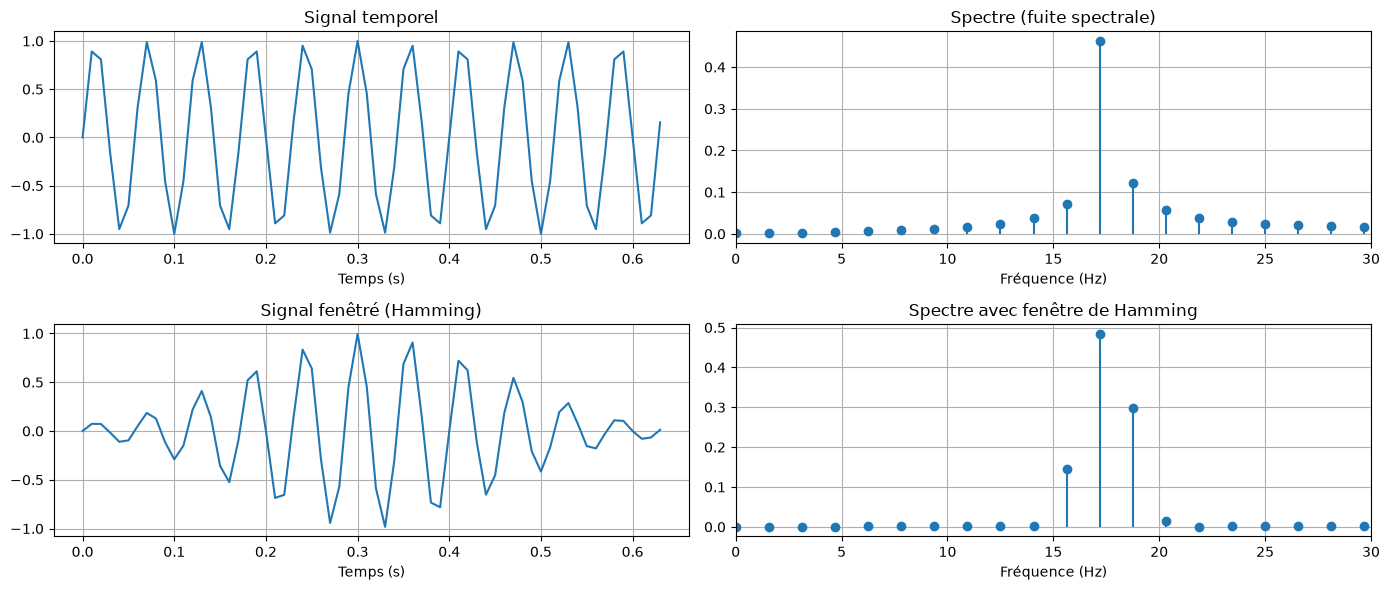

In [3]:
fs = 100  # Hz
N = 64   # nombre d'échantillons
f = 17.5  # Hz (fréquence non alignée : N*f/fs = 11.2, pas entier)
t = np.arange(N) / fs
x = np.sin(2*np.pi*f*t)

# FFT
X = fft(x)
freqs = fftfreq(N, 1/fs)

plt.figure(figsize=(14, 6))

plt.subplot(2, 2, 1)
plt.plot(t, x)
plt.title('Signal temporel')
plt.xlabel('Temps (s)')
plt.grid()

plt.subplot(2, 2, 2)
plt.stem(freqs[:N//2], np.abs(X[:N//2]) / N, basefmt=' ')
plt.title('Spectre (fuite spectrale)')
plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 30)
plt.grid()

# Fenêtre de Hamming
window = np.hamming(N)
xw = x * window
Xw = fft(xw)

plt.subplot(2, 2, 3)
plt.plot(t, xw)
plt.title('Signal fenêtré (Hamming)')
plt.xlabel('Temps (s)')
plt.grid()

plt.subplot(2, 2, 4)
plt.stem(freqs[:N//2], np.abs(Xw[:N//2]) / np.sum(window), basefmt=' ')
plt.title('Spectre avec fenêtre de Hamming')
plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 30)
plt.grid()

plt.tight_layout()
plt.show()

## 2.3 Comparaison des fenêtres

Visualisons différentes fenêtres et leurs réponses fréquentielles.

In [ ]:
N = 64
n = np.arange(N)

windows = {
    'Rectangulaire': np.ones(N),
    'Hamming': np.hamming(N),
    'Hanning': np.hanning(N),
    'Blackman': np.blackman(N),
    'Kaiser (beta=5)': np.kaiser(N, 5)
}

plt.figure(figsize=(14, 12))

for i, (name, w) in enumerate(windows.items()):
    # Réponse fréquentielle
    W = fft(w, 1024)
    W_mag = 20 * np.log10(np.abs(fftshift(W)) + 1e-12)
    freqs = np.linspace(-0.5, 0.5, 1024)
    
    plt.subplot(len(windows), 2, 2*i+1)
    plt.plot(n, w)
    plt.title(f'{name} (temporel)')
    plt.grid()
    
    plt.subplot(len(windows), 2, 2*i+2)
    plt.plot(freqs, W_mag)
    plt.title(f'{name} (fréquentiel)')
    plt.grid()
    plt.ylim(-80, 5)
    plt.xlim(-0.5, 0.5)

plt.tight_layout()
plt.show()

## 2.4 Zero-padding

Le zero-padding permet d'augmenter la résolution apparente du spectre (meilleure visualisation).

In [ ]:
fs = 100
N = 16
f = 10
t = np.arange(N) / fs
x = np.sin(2*np.pi*f*t) + 0.5*np.sin(2*np.pi*25*t)

N_ffts = [16, 64, 256]

plt.figure(figsize=(14, 5))
for i, N_fft in enumerate(N_ffts):
    X = fft(x, N_fft)
    freqs = fftfreq(N_fft, 1/fs)
    
    plt.subplot(1, 3, i+1)
    plt.stem(freqs[:N_fft//2], np.abs(X[:N_fft//2]) / N, basefmt=' ')
    plt.title(f'Zero-padding : N={N_fft}')
    plt.xlabel('Fréquence (Hz)')
    plt.xlim(0, 40)
    plt.grid()

plt.tight_layout()
plt.show()

# 3. Atelier : Analyse spectrale d'un signal réel

Nous allons appliquer les techniques vues ci-dessus à un signal audio (ou synthétique).

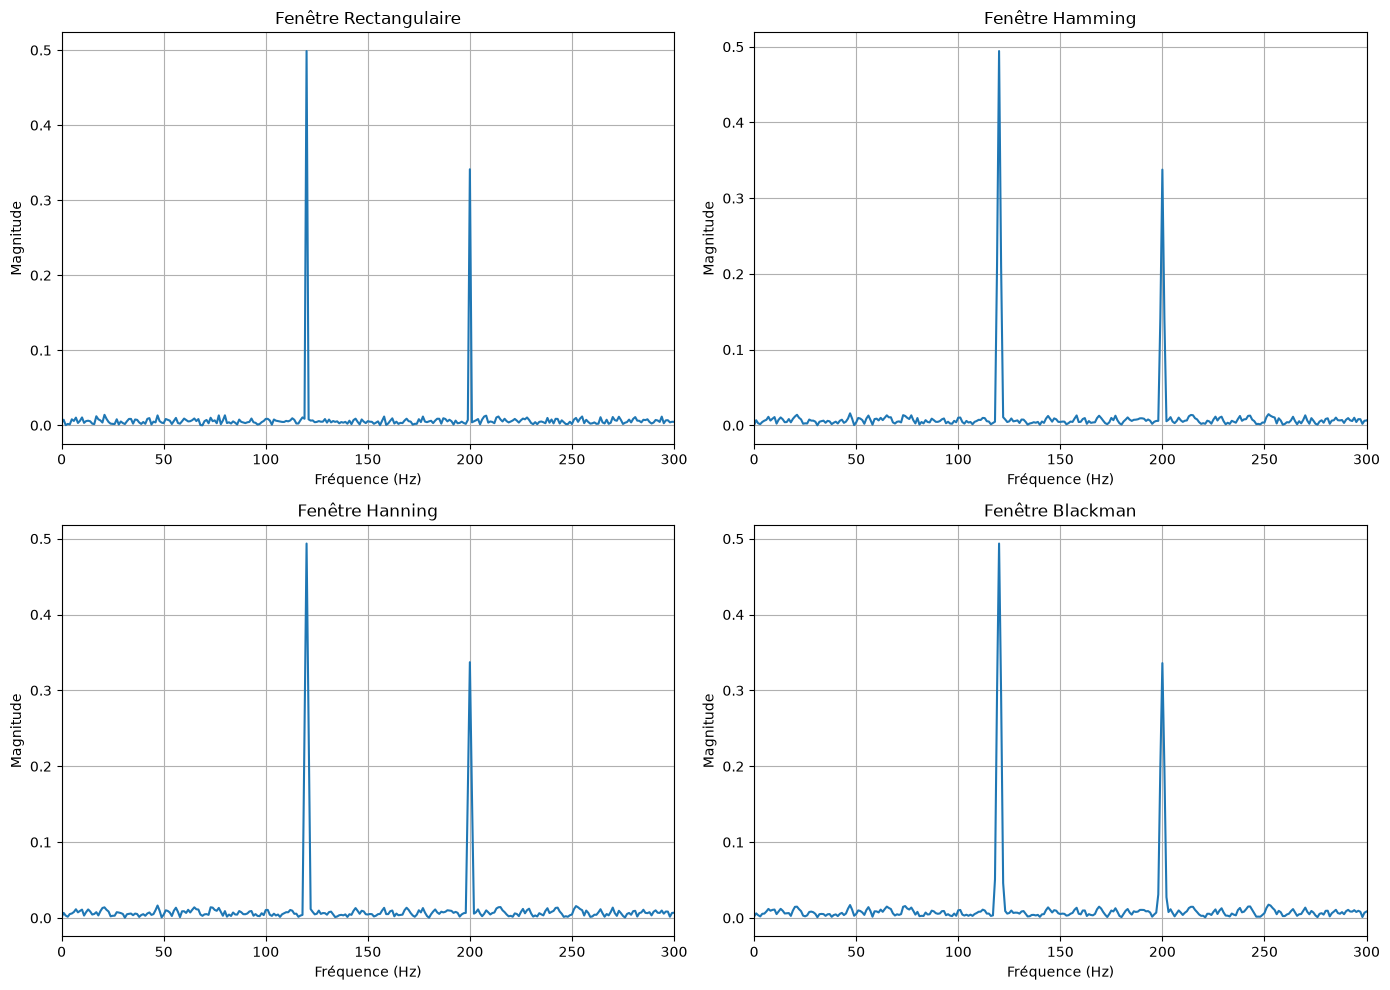

In [4]:
# Génération d'un signal de test : deux sinusoïdes + bruit
fs = 1000
duration = 1.0
t = np.linspace(0, duration, int(fs*duration), endpoint=False)

f1, f2 = 120, 200
x = np.sin(2*np.pi*f1*t) + 0.7*np.sin(2*np.pi*f2*t) + 0.2*np.random.randn(len(t))

# Analyse avec différentes fenêtres
N = len(x)
windows_test = {
    'Rectangulaire': np.ones(N),
    'Hamming': np.hamming(N),
    'Hanning': np.hanning(N),
    'Blackman': np.blackman(N)
}

plt.figure(figsize=(14, 10))

for i, (name, w) in enumerate(windows_test.items()):
    xw = x * w
    X = fft(xw)
    freqs = fftfreq(N, 1/fs)[:N//2]
    
    plt.subplot(2, 2, i+1)
    plt.plot(freqs, np.abs(X[:N//2]) / np.sum(w))
    plt.title(f'Fenêtre {name}')
    plt.xlabel('Fréquence (Hz)')
    plt.ylabel('Magnitude')
    plt.xlim(0, 300)
    plt.grid()

plt.tight_layout()
plt.show()

# 4. Exercices – Semaine 8

## Exercice 1 – DFT et FFT

1. Générer un signal $x[n] = \cos(2\pi f_0 n / f_s)$ pour $n=0,\dots,63$, avec $f_0 = 10$ Hz et $f_s = 64$ Hz.
2. Calculer la DFT manuellement pour quelques valeurs de $k$ (par exemple $k=0,1,2$).
3. Vérifier avec `numpy.fft.fft`.
4. Que vaut $X[10]$ ? Pourquoi ?

**Code** :

x[n] = cos(2π·10·n/64), N = 64, fₑ = 64 Hz, donc la fréquence f₀ = 10 Hz tombe exactement sur le bin k₀ = f₀·N/fₑ = 10.

- **DFT manuelle** : X[0] = X[1] = X[2] = 0 (aucune composante à ces fréquences).
- **Vérification FFT** : les valeurs de la FFT sont identiques à celles de la DFT manuelle (écart de l'ordre de 1e-14).
- **X[10] = 32 = N/2** (et X[54] = 32 aussi). Explication : cos(ω₀n) = ½(e^(jω₀n) + e^(−jω₀n)). Chaque exponentielle complexe a une DFT égale à N en un seul bin, grâce à l'orthogonalité des exponentielles sur N points. On obtient donc N/2 en k = 10 et en k = N − 10 = 54, et 0 partout ailleurs.

In [ ]:
import numpy as np
from scipy.fft import fft

N, fs, f0 = 64, 64, 10
n = np.arange(N)
x = np.cos(2*np.pi*f0*n/fs)

# DFT manuelle pour quelques valeurs de k
for k in (0, 1, 2, 10, 54):
    Xk = np.sum(x * np.exp(-2j*np.pi*k*n/N))
    print(f"X[{k}] (manuel) = {np.round(Xk, 6)}")

# Vérification avec la FFT
X = fft(x)
print("X[10] (FFT) =", np.round(X[10], 6))
print("X[54] (FFT) =", np.round(X[54], 6))
print("Bins non nuls :", np.where(np.abs(X) > 1e-9)[0])   # [10 54]

In [ ]:
N = 64
fs = 64
f0 = 10
n = np.arange(N)
x = np.cos(2*np.pi*f0*n/fs)

# DFT manuelle pour k=0,1,2
k_vals = [0, 1, 2]
for k in k_vals:
    Xk = np.sum(x * np.exp(-2j*np.pi*k*n/N))
    print(f"X[{k}] = {Xk:.2f}")

# Vérification avec FFT
X = fft(x)
print(f"X[10] (FFT) = {X[10]:.2f}")
print(f"X[54] (FFT) = {X[54]:.2f}")
# X[10] est non nul car 10 Hz correspond à k=10 (fréquence alignée)

## Exercice 2 – Fuite spectrale et fenêtrage

1. Générer $x[n] = \sin(2\pi f_1 n / f_s) + \sin(2\pi f_2 n / f_s)$ avec $f_1 = 15$ Hz, $f_2 = 16$ Hz, $f_s = 64$ Hz, $N=64$.
2. Calculer et tracer le spectre sans fenêtre.
3. Appliquer une fenêtre de Hamming et tracer le nouveau spectre.
4. Commenter la résolution et la fuite spectrale dans les deux cas.

**Code** :

x[n] = sin(2π·15n/64) + sin(2π·16n/64), N = 64, fₑ = 64 Hz. Les deux fréquences tombent exactement sur les bins k = 15 et k = 16.

**Sans fenêtre** : deux raies nettes à 15 et 16 Hz, d'amplitude 0,5 chacune. Il n'y a **aucune fuite** sur la grille de la FFT (résidu ≈ 1e-15), car 15 et 16 périodes entières tiennent dans la fenêtre : les bins tombent sur les zéros de la réponse de la fenêtre rectangulaire. La résolution est maximale.

**Avec Hamming** : le lobe principal est deux fois plus large (±2 bins), donc les deux raies se fondent en un plateau sur 4 bins (14 à 17 Hz : 0,215 ; 0,283 ; 0,283 ; 0,215). Les pics tombent à 0,283 au lieu de 0,5 et les deux fréquences ne sont plus distinguables : la **résolution est dégradée**. En contrepartie, les lobes secondaires sont beaucoup plus bas : dans le spectre continu (avec zero-padding), ≈ −45 dB vers 25-30 Hz contre ≈ −29 dB sans fenêtre.

**Conclusion** : quand les fréquences sont alignées sur les bins, la fenêtre est inutile et même nuisible. Elle est utile seulement quand les fréquences ne sont pas alignées (fuite) ou pour détecter une composante faible à côté d'une forte.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq

N, fs = 64, 64
n = np.arange(N)
x = np.sin(2*np.pi*15*n/fs) + np.sin(2*np.pi*16*n/fs)
w = np.hamming(N)

X  = np.abs(fft(x)) / N                    # sans fenêtre
Xw = np.abs(fft(x*w)) / np.sum(w)          # Hamming
freqs = fftfreq(N, 1/fs)[:N//2]

# Spectre continu (zero-padding) pour voir ce que la grille cache
N_fft = 1024
f_fin = np.arange(N_fft//2) * fs / N_fft
Xz  = np.abs(fft(x, N_fft))[:N_fft//2] / N
Xwz = np.abs(fft(x*w, N_fft))[:N_fft//2] / np.sum(w)

print("Bins 13 à 18, sans fenêtre :", np.round(X[13:19], 4))
print("Bins 12 à 19, Hamming      :", np.round(Xw[12:20], 4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, spec, fin, titre in ((ax[0], X, Xz, "Sans fenêtre"), (ax[1], Xw, Xwz, "Avec Hamming")):
    a.stem(freqs, spec[:N//2], basefmt=" ")
    a.plot(f_fin, fin, "r--", lw=1, label="spectre continu (zero-padding)")
    a.set_xlim(10, 20); a.set_title(titre); a.set_xlabel("Fréquence (Hz)")
    a.grid(True, alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

In [ ]:
N = 64
fs = 64
n = np.arange(N)
f1, f2 = 15, 16
x = np.sin(2*np.pi*f1*n/fs) + np.sin(2*np.pi*f2*n/fs)

# Sans fenêtre
X = fft(x)
freqs = np.fft.fftfreq(N, 1/fs)[:N//2]

# Avec Hamming
xw = x * np.hamming(N)
Xw = fft(xw)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.stem(freqs, np.abs(X[:N//2]) / N, basefmt=' ')
plt.title('Sans fenêtre')
plt.xlabel('Fréquence (Hz)')
plt.xlim(10, 20)
plt.grid()

plt.subplot(1, 2, 2)
plt.stem(freqs, np.abs(Xw[:N//2]) / np.sum(np.hamming(N)), basefmt=' ')
plt.title('Avec Hamming')
plt.xlabel('Fréquence (Hz)')
plt.xlim(10, 20)
plt.grid()
plt.show()

## Exercice 3 – Choix de la fenêtre

On considère un signal composé de trois sinusoïdes très proches : 100.0 Hz, 100.5 Hz, 101.0 Hz.

1. Générer ce signal sur 1 seconde à $f_s = 500$ Hz.
2. Tester plusieurs fenêtres (rectangulaire, Hamming, Blackman).
3. Quelle fenêtre permet de distinguer les trois fréquences ? Quelle fenêtre donne la meilleure dynamique (lobes secondaires les plus faibles) ?
4. Proposer une stratégie pour améliorer la résolution.

**Code** :

Signal : 100,0 ; 100,5 et 101,0 Hz, fₑ = 500 Hz. L'écart entre raies est Δf = 0,5 Hz.

**Résolution** : elle ne dépend que de la durée T (pas de fₑ). Avec T = 1 s, 1/T = 1 Hz > Δf. **Aucune fenêtre** ne permet donc de distinguer les trois fréquences sur 1 seconde. Sur la grille FFT à 1 Hz on voit seulement deux bins forts (100 et 101 Hz, 0,593 chacun) ; la composante à 100,5 Hz se perd entre les deux.

**Durée minimale pour séparer les 3 raies** (simulation avec zero-padding) :

| Durée T | Rectangulaire | Hamming | Blackman |
|---|---|---|---|
| 1 s | non | non | non |
| 2 s | oui | non | non |
| 3 s | oui | oui | non |
| 6 s | oui | oui | oui |

Ordre de grandeur théorique : T > 1/Δf = 2 s (rect.), ≈ 2/Δf = 4 s (Hamming), ≈ 3/Δf = 6 s (Blackman), car le lobe principal s'élargit avec la fenêtre.

**Meilleure résolution** : fenêtre rectangulaire (lobe principal le plus étroit).
**Meilleure dynamique** (lobes secondaires les plus faibles, mesurés à plus de 5 Hz du signal, T = 1 s) : Blackman (≈ −56 dB), puis Hamming (≈ −37 dB), puis rectangulaire (≈ −19 dB).

**Stratégie pour améliorer la résolution** : augmenter la durée d'acquisition T (donc N). Augmenter fₑ n'aide pas, et le zero-padding ne fait qu'interpoler. Choisir la fenêtre selon le besoin : rectangulaire si les raies ont des amplitudes comparables et qu'on veut la résolution, Blackman si une raie faible est voisine d'une raie forte.

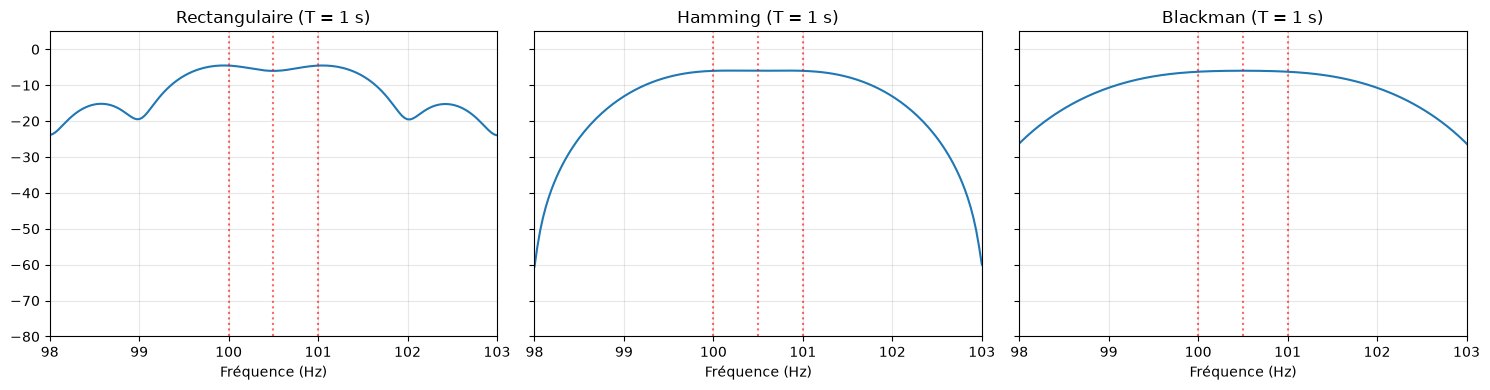

 T (s) | Rectangulaire |       Hamming |      Blackman
     1 |      2 pic(s) |      0 pic(s) |      1 pic(s)
     2 |      3 pic(s) |      1 pic(s) |      0 pic(s)
     3 |      3 pic(s) |      3 pic(s) |      2 pic(s)
     4 |      3 pic(s) |      3 pic(s) |      0 pic(s)
     6 |      3 pic(s) |      3 pic(s) |      3 pic(s)
     8 |      3 pic(s) |      3 pic(s) |      3 pic(s)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft
from scipy.signal import find_peaks

fs = 500
freqs_signal = [100.0, 100.5, 101.0]
fenetres = {"Rectangulaire": np.ones, "Hamming": np.hamming, "Blackman": np.blackman}

def spectre(T, win, zp=32):
    N = int(fs * T)
    t = np.arange(N) / fs
    x = sum(np.sin(2*np.pi*f*t) for f in freqs_signal)
    w = win(N)
    N_fft = zp * N
    X = np.abs(fft(x * w, N_fft))[:N_fft//2] / np.sum(w)
    return np.arange(N_fft//2) * fs / N_fft, X

# Spectres pour T = 1 s (échelle dB)
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, (nom, win) in zip(ax, fenetres.items()):
    f, X = spectre(1.0, win)
    a.plot(f, 20*np.log10(X + 1e-12))
    for f0 in freqs_signal:
        a.axvline(f0, color="r", ls=":", alpha=0.6)
    a.set_xlim(98, 103); a.set_ylim(-80, 5)
    a.set_title(f"{nom} (T = 1 s)"); a.set_xlabel("Fréquence (Hz)"); a.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# Combien de raies sépare-t-on selon la durée T ? (pics à moins de 0,15 Hz des vraies fréquences)
print(f"{'T (s)':>6} | " + " | ".join(f"{nom:>13}" for nom in fenetres))
for T in (1, 2, 3, 4, 6, 8):
    ligne = []
    for nom, win in fenetres.items():
        f, X = spectre(T, win)
        m = (f > 99) & (f < 102)
        pk, _ = find_peaks(X[m], prominence=0.02 * X[m].max())
        proches = [p for p in f[m][pk] if min(abs(p - f0) for f0 in freqs_signal) < 0.15]
        ligne.append(f"{len(proches)} pic(s)")
    print(f"{T:>6} | " + " | ".join(f"{s:>13}" for s in ligne))

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft
from scipy.signal import find_peaks

fs = 500
freqs_signal = [100.0, 100.5, 101.0]
fenetres = {"Rectangulaire": np.ones, "Hamming": np.hamming, "Blackman": np.blackman}

def spectre(T, win, zp=32):
    N = int(fs * T)
    t = np.arange(N) / fs
    x = sum(np.sin(2*np.pi*f*t) for f in freqs_signal)
    w = win(N)
    N_fft = zp * N
    X = np.abs(fft(x * w, N_fft))[:N_fft//2] / np.sum(w)
    return np.arange(N_fft//2) * fs / N_fft, X

# Spectres pour T = 1 s (échelle dB)
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, (nom, win) in zip(ax, fenetres.items()):
    f, X = spectre(1.0, win)
    a.plot(f, 20*np.log10(X + 1e-12))
    for f0 in freqs_signal:
        a.axvline(f0, color="r", ls=":", alpha=0.6)
    a.set_xlim(98, 103); a.set_ylim(-80, 5)
    a.set_title(f"{nom} (T = 1 s)"); a.set_xlabel("Fréquence (Hz)"); a.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# Combien de raies sépare-t-on selon la durée T ? (pics à moins de 0,15 Hz des vraies fréquences)
print(f"{'T (s)':>6} | " + " | ".join(f"{nom:>13}" for nom in fenetres))
for T in (1, 2, 3, 4, 6, 8):
    ligne = []
    for nom, win in fenetres.items():
        f, X = spectre(T, win)
        m = (f > 99) & (f < 102)
        pk, _ = find_peaks(X[m], prominence=0.02 * X[m].max())
        proches = [p for p in f[m][pk] if min(abs(p - f0) for f0 in freqs_signal) < 0.15]
        ligne.append(f"{len(proches)} pic(s)")
    print(f"{T:>6} | " + " | ".join(f"{s:>13}" for s in ligne))

In [ ]:
fs = 500
duration = 1.0
N = int(fs * duration)
t = np.linspace(0, duration, N, endpoint=False)

freqs_signal = [100.0, 100.5, 101.0]
x = np.zeros(N)
for f in freqs_signal:
    x += np.sin(2*np.pi*f*t)

windows = {
    'Rectangulaire': np.ones(N),
    'Hamming': np.hamming(N),
    'Hanning': np.hanning(N),
    'Blackman': np.blackman(N)
}

plt.figure(figsize=(14, 10))
for i, (name, w) in enumerate(windows.items()):
    xw = x * w
    X = fft(xw)
    freqs = fftfreq(N, 1/fs)[:N//2]
    
    plt.subplot(2, 2, i+1)
    plt.plot(freqs, 20*np.log10(np.abs(X[:N//2]) / np.sum(w) + 1e-12))
    plt.title(f'Fenêtre {name}')
    plt.xlabel('Fréquence (Hz)')
    plt.xlim(98, 103)
    plt.ylim(-80, 5)
    plt.grid()

plt.tight_layout()
plt.show()

# La fenêtre rectangulaire donne la meilleure résolution, mais les lobes secondaires sont élevés.
# Blackman donne la meilleure dynamique, mais une résolution moindre.
# Pour améliorer la résolution, il faut augmenter N (durée d'acquisition).

## Exercice 4 – Zero-padding et résolution

1. Générer $x[n] = \sin(2\pi 0.4 n) + \sin(2\pi 0.45 n)$ pour $n=0,\dots,31$.
2. Calculer la FFT avec différents zero-padding ($N_{fft} = 32, 64, 256$).
3. Observer l'effet du zero-padding sur le spectre.
4. Que se passe-t-il au niveau de la résolution ?

**Code** :

x[n] = sin(2π·0,4·n) + sin(2π·0,45·n), n = 0, …, 31. Les fréquences sont données en **cycles par échantillon** : 0,40 et 0,45 (soit ω = 2,513 et 2,827 rad/éch.). L'écart est Δf = 0,05.

**Résolution** : elle est fixée par N = 32 : 1/N = 0,031 < Δf = 0,05, donc les deux composantes sont **déjà résolues** avec 32 points.

**Effet du zero-padding** (pics mesurés en cycles/éch.) :
- N_fft = 32 : pics sur une grille grossière, à 0,406 et 0,469 (hauteurs 0,46 et 0,33), donc positions et amplitudes faussées.
- N_fft = 64 : pics à 0,406 et 0,453.
- N_fft = 256 : pics à 0,402 et 0,453 (hauteurs ≈ 0,48 et 0,49).

Le zero-padding **n'améliore pas la résolution** (il n'ajoute aucune information), il **interpole** le spectre pour lire correctement la position et la hauteur des pics. Les deux pics ne sont pas « confondus » comme l'indique le notebook : ils sont séparés par un creux (à environ 38 % de la hauteur des pics). Leurs positions sont légèrement décalées par rapport à 0,40 et 0,45 car elles sont proches de la fréquence de Nyquist (0,5), donc proches de leurs images en fréquences négatives.

N_fft =  32 : pics à [0.406 0.469], hauteurs [0.458 0.328]
N_fft =  64 : pics à [0.406 0.453], hauteurs [0.458 0.489]
N_fft = 256 : pics à [0.402 0.453], hauteurs [0.477 0.489]


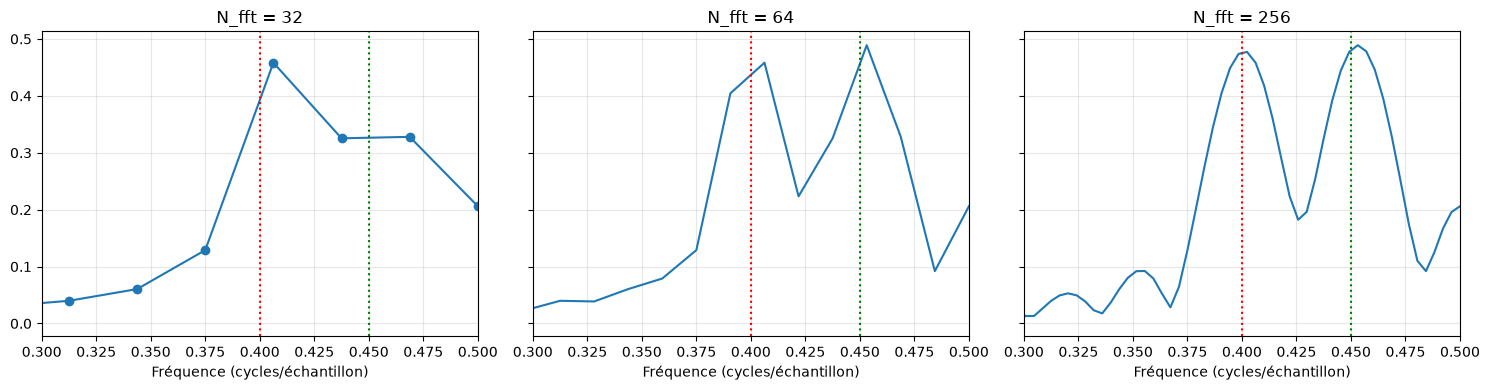


Résolution : 1/N = 0.0312 < Δf = 0.05  -> pics résolus avec N = 32


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft
from scipy.signal import find_peaks

N = 32
n = np.arange(N)
x = np.sin(2*np.pi*0.4*n) + np.sin(2*np.pi*0.45*n)

fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, N_fft in zip(ax, (32, 64, 256)):
    X = np.abs(fft(x, N_fft))[:N_fft//2 + 1] / N
    f = np.arange(N_fft//2 + 1) / N_fft                # fréquence en cycles/échantillon, de 0 à 0,5
    a.plot(f, X, "o-" if N_fft == 32 else "-")
    a.axvline(0.40, color="r", ls=":"); a.axvline(0.45, color="g", ls=":")
    a.set_xlim(0.3, 0.5)
    a.set_title(f"N_fft = {N_fft}"); a.set_xlabel("Fréquence (cycles/échantillon)")
    a.grid(True, alpha=0.3)
    pk, _ = find_peaks(X, height=0.2 * X.max())
    print(f"N_fft = {N_fft:>3} : pics à {f[pk].round(3)}, hauteurs {X[pk].round(3)}")
plt.tight_layout(); plt.show()

print(f"\nRésolution : 1/N = {1/N:.4f} < Δf = 0.05  -> pics résolus avec N = 32")

In [ ]:
N = 32
n = np.arange(N)
x = np.sin(2*np.pi*0.4*n) + np.sin(2*np.pi*0.45*n)

N_ffts = [32, 64, 256]

plt.figure(figsize=(14, 5))
for i, N_fft in enumerate(N_ffts):
    X = fft(x, N_fft)
    freqs = np.linspace(0, np.pi, N_fft//2)
    
    plt.subplot(1, 3, i+1)
    plt.plot(freqs, np.abs(X[:N_fft//2]) / N)
    plt.title(f'Zero-padding : N_fft={N_fft}')
    plt.xlabel('Fréquence (rad/échantillon)')
    plt.xlim(0.3, 0.55)
    plt.grid()

plt.tight_layout()
plt.show()

# Le zero-padding n'améliore pas la résolution (les deux pics restent confondus),
# mais il permet de mieux visualiser la forme du lobe.

## Exercice 5 – Spectre de phase et décalage temporel

1. Générer $x[n] = \cos(0.3\pi n)$ pour $n=0,\dots,31$.
2. Calculer le spectre de phase (argument de la FFT).
3. Décaler le signal de 3 échantillons ($y[n] = x[n-3]$) et recalculer le spectre de phase.
4. Observer la relation entre le décalage temporel et la phase de la FFT.

**Code** :

x[n] = cos(0,3πn), N = 32. Ici k₀ = 0,15·N = 4,8 n'est pas entier : il y a de la fuite spectrale, et le pic principal tombe sur le bin k = 5 (|X[5]| = 15,2 au lieu de N/2 = 16).

**Décalage** : `np.roll(x, 3)` est un décalage **circulaire**. Pour la DFT, le théorème du retard est alors exact pour tous les bins :

**Y[k] = X[k]·e^(−j2πk·3/N)**, soit **phase(Y) = phase(X) − ω_k·3** avec ω_k = 2πk/N.

La différence de phase est une **fonction linéaire de la fréquence**, de pente −3 (le retard en échantillons). Vérification numérique : l'écart avec −ω_k·3 est de 4e-15 rad sur tous les bins. Exemple au bin k = 5 : phase de X = −0,628 rad, phase de Y = 2,710 rad, différence (modulo 2π) = −2,945 rad = −2π·5·3/32.

Remarque : un vrai retard x[n−3] = cos(0,3π(n−3)) n'est pas identique à `np.roll` (le signal n'est pas périodique sur N = 32 : écart maximal 1,18 sur les 3 premiers échantillons) ; le déphasage au pic vaut alors environ −ω₀·3 = −2,827 rad.

Erreur max |mesuré - théorique| : 3.1086244689504383e-15
Bin du pic : k = 5, |X| = 15.18
Phase X = -0.628, Phase Y = 2.710, déphasage = -2.945 rad


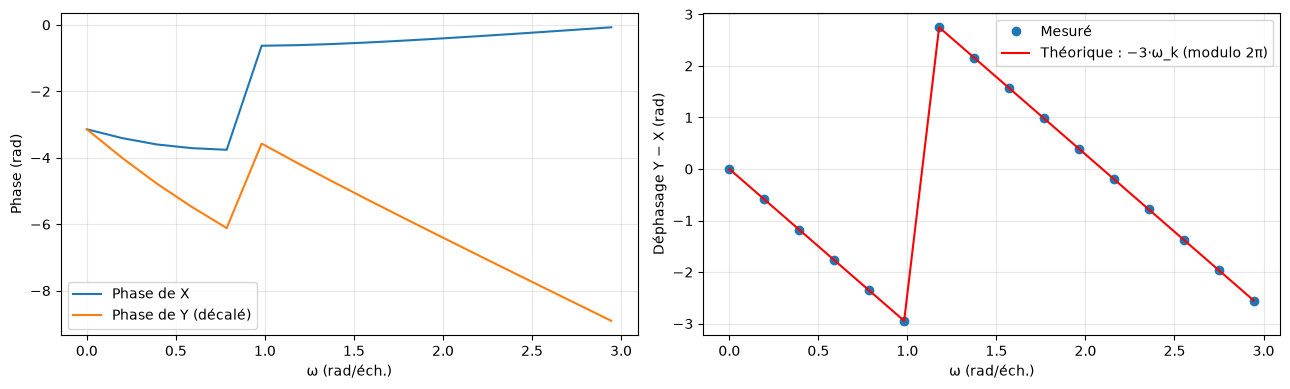

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft

N = 32
n = np.arange(N)
x = np.cos(0.3*np.pi*n)
y = np.roll(x, 3)                    # décalage circulaire de 3 échantillons

X, Y = fft(x), fft(y)
k = np.arange(N//2)
omega_k = 2*np.pi*k/N                # pulsations exactes des bins

wrap = lambda a: (a + np.pi) % (2*np.pi) - np.pi
delta = wrap(np.angle(Y[:N//2]) - np.angle(X[:N//2]))   # déphasage mesuré
theo = wrap(-omega_k * 3)                               # théorie : -ω_k · 3

print("Erreur max |mesuré - théorique| :", np.max(np.abs(wrap(delta - theo))))
k_pic = np.argmax(np.abs(X[:N//2]))
print(f"Bin du pic : k = {k_pic}, |X| = {abs(X[k_pic]):.2f}")
print(f"Phase X = {np.angle(X[k_pic]):.3f}, Phase Y = {np.angle(Y[k_pic]):.3f}, déphasage = {delta[k_pic]:.3f} rad")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(omega_k, np.unwrap(np.angle(X[:N//2])), label="Phase de X")
ax[0].plot(omega_k, np.unwrap(np.angle(Y[:N//2])), label="Phase de Y (décalé)")
ax[0].set_xlabel("ω (rad/éch.)"); ax[0].set_ylabel("Phase (rad)"); ax[0].legend()
ax[1].plot(omega_k, delta, "o", label="Mesuré")
ax[1].plot(omega_k, theo, "r-", label="Théorique : −3·ω_k (modulo 2π)")
ax[1].set_xlabel("ω (rad/éch.)"); ax[1].set_ylabel("Déphasage Y − X (rad)"); ax[1].legend()
for a in ax:
    a.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
N = 32
n = np.arange(N)
x = np.cos(0.3*np.pi*n)
y = np.roll(x, 3)  # décalage de 3

X = fft(x)
Y = fft(y)
freqs = np.linspace(0, np.pi, N//2)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs, np.unwrap(np.angle(X[:N//2])), label='Phase originale')
plt.plot(freqs, np.unwrap(np.angle(Y[:N//2])), label='Phase décalée')
plt.xlabel('Fréquence (rad/échantillon)')
plt.ylabel('Phase (rad)')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.stem(n, x, basefmt=' ', label='Original')
plt.stem(n, y, basefmt=' ', linefmt='r-', markerfmt='ro', label='Décalé de 3')
plt.legend()
plt.grid()
plt.show()

print("Le décalage temporel introduit un déphasage linéaire : phase_Y = phase_X - omega*3.")

## Exercice 6 – Analyse spectrale d'un fichier audio

1. Charger un fichier audio (WAV) ou utiliser un signal synthétique.
2. Afficher le signal temporel et son spectre avec une FFT.
3. Identifier les composantes fréquentielles principales.
4. Appliquer un filtre coupe-bande pour supprimer une fréquence parasite (exemple : 50 Hz).
5. Comparer les spectres avant et après filtrage.

**Code** (adaptez si vous avez un fichier audio) :

Signal synthétique : sin(2π·120t) + 0,5·sin(2π·50t) + bruit (σ = 0,1), fₑ = 1 kHz, T = 2 s.

3. **Composantes principales** (amplitudes lues avec 2|X|/N) : **120 Hz** (amplitude ≈ 1) et **50 Hz** (amplitude ≈ 0,5, la perturbation à supprimer), plus un fond de bruit large bande.
4. **Filtre coupe-bande** : on utilise un filtre IIR (notch) `signal.iirnotch(50, Q=30, fs=1000)` appliqué avec `filtfilt` (phase nulle). Son gain vaut 0 à 50 Hz et 0,9999 à 120 Hz ; la bande à −3 dB va de 49,2 à 50,8 Hz (≈ f₀/Q ≈ 1,7 Hz).
5. **Comparaison avant/après** : l'amplitude à 50 Hz passe de 0,50 à ≈ 0,03 (−24 dB environ). Le résidu vient du régime transitoire du filtre au début du signal. À 120 Hz l'amplitude reste ≈ 1,0 : la composante utile est conservée.

**Variante par annulation de bins FFT** : il faut annuler **les deux** bins symétriques (+50 Hz et −50 Hz). Alors l'amplitude à 50 Hz tombe à ≈ 0 (4e-18). Cette méthode n'est exacte que parce que 50 Hz tombe sur un bin (T = 2 s → bins tous les 0,5 Hz), et elle est non causale : ce n'est pas un vrai filtre utilisable en temps réel.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import fft, fftfreq

np.random.seed(0)
fs, duration = 1000, 2.0
t = np.linspace(0, duration, int(fs*duration), endpoint=False)
x = np.sin(2*np.pi*120*t) + 0.5*np.sin(2*np.pi*50*t) + 0.1*np.random.randn(len(t))

N = len(x)
freqs = fftfreq(N, 1/fs)[:N//2]
amp = lambda s: 2*np.abs(fft(s))[:N//2] / N          # amplitude réelle des sinusoïdes

# 3. Composantes principales
pk, _ = signal.find_peaks(amp(x), height=0.2)
print("Composantes détectées (Hz) :", freqs[pk], "| amplitudes :", amp(x)[pk].round(3))

# 4a. Filtre coupe-bande IIR (notch) à 50 Hz
b, a = signal.iirnotch(50, Q=30, fs=fs)
x_notch = signal.filtfilt(b, a, x)

# 4b. Variante FFT : annuler les DEUX bins (+50 Hz et -50 Hz)
X = fft(x)
k50 = int(round(50 * N / fs))
X[k50] = 0
X[N - k50] = 0
x_fft = np.fft.ifft(X).real

# 5. Spectres avant / après, calculés à partir des signaux filtrés
i50, i120 = int(50*N/fs), int(120*N/fs)
for nom, s in (("Original", x), ("Notch IIR", x_notch), ("FFT 2 bins", x_fft)):
    print(f"{nom:>10} : amplitude à 50 Hz = {amp(s)[i50]:.4f}, à 120 Hz = {amp(s)[i120]:.4f}")

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
ax[0, 0].plot(t[:500], x[:500], label="Original")
ax[0, 0].plot(t[:500], x_notch[:500], label="Après notch")
ax[0, 0].set_title("Signal temporel (extrait)"); ax[0, 0].set_xlabel("Temps (s)"); ax[0, 0].legend()
for a_, s, titre in ((ax[0, 1], x, "Spectre original"),
                     (ax[1, 0], x_notch, "Spectre après notch IIR"),
                     (ax[1, 1], x_fft, "Spectre après annulation FFT (2 bins)")):
    a_.plot(freqs, amp(s)); a_.set_xlim(0, 200); a_.set_ylim(0, 1.1)
    a_.set_title(titre); a_.set_xlabel("Fréquence (Hz)"); a_.set_ylabel("Amplitude")
for a_ in ax.flat:
    a_.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

In [4]:
# Exemple avec un signal synthétique contenant du bruit à 50 Hz
fs = 1000
duration = 2.0
t = np.linspace(0, duration, int(fs*duration), endpoint=False)

# Signal utile + bruit 50 Hz
x = np.sin(2*np.pi*120*t) + 0.5*np.sin(2*np.pi*50*t) + 0.1*np.random.randn(len(t))

# FFT
X = fft(x)
freqs = fftfreq(len(x), 1/fs)[:len(x)//2]

plt.figure(figsize=(14, 10))
plt.subplot(2, 2, 1)
plt.plot(t[:500], x[:500])
plt.title('Signal temporel (extrait)')
plt.grid()

plt.subplot(2, 2, 2)
plt.plot(freqs, np.abs(X[:len(x)//2]) / len(x))
plt.title('Spectre original')
plt.xlim(0, 200)
plt.grid()

# Filtrage simple : on supprime la composante 50 Hz dans le domaine fréquentiel
X_filtre = X.copy()
indices = np.where(np.abs(freqs - 50) < 0.5)[0]
X_filtre[indices] = 0
indices_neg = np.where(np.abs(freqs + 50) < 0.5)[0]
X_filtre[indices_neg + len(x)//2] = 0

x_filtre = np.fft.ifft(X_filtre).real

plt.subplot(2, 2, 3)
plt.plot(freqs, np.abs(X_filtre[:len(x)//2]) / len(x))
plt.title('Spectre filtré (50 Hz supprimé)')
plt.xlim(0, 200)
plt.grid()

plt.subplot(2, 2, 4)
plt.plot(t[:500], x_filtre[:500])
plt.title('Signal filtré (extrait)')
plt.grid()

plt.tight_layout()
plt.show()

NameError: name 'fftfreq' is not defined

# 5. Livrable Semaine 8

- Remplir les cellules de code avec vos solutions.
- Répondre aux questions théoriques dans les cellules markdown.
- Inclure des commentaires explicatifs.
- Rendre le notebook complet (cellules exécutées).

**Date de rendu** : à définir par l'enseignant.

---